---
title: "Exploratory Data Analysis"
date: last-modified
date-format: "YYYY-MM-DD HH:mm:ss"
format:
  html:
    toc: true
    toc-depth: 5
    toc-location: left
    embed-resources: true
    page-layout: full
---
<style>
  .cell-output-display img {
    width: 100% !important;
    max-width: 900px !important;
    height: auto !important;
  }
</style>
***

This notebook introduces the Oulanka Mycopins project datasets: Community (OTU), Environment, and Organism (sample). It focuses specifically on an exploration of Saproxylic Fungi, a subset of the community dataset.

In [1]:
# Load libraries and support functions
source("../src/oulanka.R")
source("../src/make_plots.R")

## 1. Source Datasets

### Community dataset

In [2]:
community_df <- get_community_data()

In [3]:
head(community_df)

Acephala,Acrocalymma medicaginis,Agaricales,Agaricus bisporus,Allantophomopsis,Allantophomopsis cytisporea,Alternaria,Alternaria alternata,Amanita,Amphinema,⋯,Vitreoporus dichrous,Wallemia canadensis,Wallemia mellicola,Wickerhamomyces anomalus,Xenasmatella,Xenasmatella vaga,Xenopolyscytalum,Xylaria cubensis,Xylographa,Yamadamyces rosulatus
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,0,0,0,0,1,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,2,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,4,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,4,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [4]:
length(names(community_df))

[1] 359

In [5]:
head(names(community_df))

[1] "Acephala"                    "Acrocalymma medicaginis"    
[3] "Agaricales"                  "Agaricus bisporus"          
[5] "Allantophomopsis"            "Allantophomopsis cytisporea"

In [6]:
tail(names(community_df))

[1] "Xenasmatella"          "Xenasmatella vaga"     "Xenopolyscytalum"     
[4] "Xylaria cubensis"      "Xylographa"            "Yamadamyces rosulatus"

In [7]:
community_names <- names(community_df)
print(paste("Has", length(community_names), "fungal communities"))

# Remove the unidentified Fungi community
community_names <- community_names[community_names != "Fungi"]
print(paste("Has", length(community_names), "identifiable fungal communities")) 

# Split the strings by whitespace and count the number of tokens in each
# strsplit returns a list; we use sapply to get the length (count) of each element
token_counts <- sapply(strsplit(community_names, "\\s+"), length)

species_community_names <- community_names[token_counts > 1]
print(paste("Has", length(species_community_names), "identifiable species-level fungal communities")) 

genus_community_names <- community_names[token_counts == 1]
print(paste("Has", length(genus_community_names), "identifiable genus-only-level fungal communities")) 

[1] "Has 359 fungal communities"
[1] "Has 358 identifiable fungal communities"
[1] "Has 219 identifiable species-level fungal communities"
[1] "Has 139 identifiable genus-only-level fungal communities"


**The dataset identified 359 fungal communities with 219 fungal communities identified a the species level, 139 fungal communities identified at the genus level only, and one fungal community not identified at the species or genus level.**

### Environment dataset

In [8]:
environment_df <- get_environment_data()

In [9]:
head(environment_df)

Transect,Tag,Sample.Number,Date.Collected,Days.Elapsed,Weeks.Elapsed,Months.Elapsed,Season,Wood.Type,Wood.Texture,Forward.Primer,Reverse.Primer
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
A,1,018561A,07/01/2022,13,2,2,Summer,Pine,Softwood,CACACGATCTGTGARTCATCGAATCTTTG,CACACGCTGTTCCTCCGCTTATTGATATGC
A,4,018561C,07/01/2022,13,2,2,Summer,Birch,Hardwood,CACATAGTCTGTGARTCATCGAATCTTTG,CACATGTCGTTCCTCCGCTTATTGATATGC
A,5,018561E,07/01/2022,13,2,2,Summer,Spruce,Softwood,CACATGACTTGTGARTCATCGAATCTTTG,CACGCAGCATTCCTCCGCTTATTGATATGC
A,6,018562C,07/15/2022,27,4,2,Summer,Birch,Hardwood,CACGATCAGTGTGARTCATCGAATCTTTG,CACTAGCGCTTCCTCCGCTTATTGATATGC
A,7,018562E,07/15/2022,27,4,2,Summer,Spruce,Softwood,CACGTGCTCTGTGARTCATCGAATCTTTG,CACTATGCATTCCTCCGCTTATTGATATGC
A,8,018579B,08/05/2023,413,59,15,Summer,Pine,Softwood,CACTATAGCTGTGARTCATCGAATCTTTG,CACTCACACTTCCTCCGCTTATTGATATGC


In [10]:
length(names(environment_df))

[1] 12

In [11]:
names(environment_df)

[1] "Transect"       "Tag"            "Sample.Number"  "Date.Collected"
 [5] "Days.Elapsed"   "Weeks.Elapsed"  "Months.Elapsed" "Season"        
 [9] "Wood.Type"      "Wood.Texture"   "Forward.Primer" "Reverse.Primer"

### Organisms dataset

In [12]:
organisms_df <- get_organisms_data()

In [13]:
nrow(organisms_df)

[1] 746

In [14]:
head(organisms_df)

organism,match.source,match.percent_identity,match.evalue,match.bit_score,match.accession,match.tax_id,gbif.match_type,gbif.usage_key,gbif.scientific_name,⋯,gbif.class,gbif.order,gbif.family,gbif.genus,gbif.taxon_rank,gbif.status,gbif.scientific_name_authorship,fungal_traits.primary_lifestyle,fungal_traits.secondary_lifestyle,is_saproxylic
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Acephala,BLAST,99.52830,1.02046e-102,387.070,EU434832,519223,EXACT,2581337,Acephala Grünig & T.N.Sieber,⋯,Leotiomycetes,Helotiales,Vibrisseaceae,Acephala,GENUS,ACCEPTED,Grünig & T.N.Sieber,soil_saprotroph,root_endophyte_dark_septate,no
Acephala applanata,BLAST,92.50000,2.26257e-89,342.750,EF093158,327282,EXACT,2581338,Acephala applanata Grünig & T.N.Sieber,⋯,Leotiomycetes,Helotiales,Vibrisseaceae,Acephala,SPECIES,ACCEPTED,Grünig & T.N.Sieber,soil_saprotroph,root_endophyte_dark_septate,no
Acremonium,BLAST,99.61390,4.09734e-129,473.863,MT294401,2046025,EXACT,2560451,"Acremonium Link, 1809",⋯,Sordariomycetes,Hypocreales,Bionectriaceae,Acremonium,GENUS,ACCEPTED,"Link, 1809",unspecified_saprotroph,foliar_endophyte,no
Acremonium alternatum,BLAST,100.00000,4.17743e-134,490.482,OR761512,45275,EXACT,2562344,Acremonium alternatum Link,⋯,Sordariomycetes,Hypocreales,Bionectriaceae,Acremonium,SPECIES,ACCEPTED,Link,unspecified_saprotroph,foliar_endophyte,no
Acrocalymma medicaginis,BLAST,100.00000,1.39800e-123,455.396,MK119225,1589763,EXACT,2615650,Acrocalymma medicaginis Alcorn & J.A.G.Irwin,⋯,Dothideomycetes,Pleosporales,Acrocalymmaceae,Acrocalymma,SPECIES,ACCEPTED,Alcorn & J.A.G.Irwin,wood_saprotroph,NA,no
Aequabiliella palatina,BLAST,98.82812,8.40558e-124,457.243,PP523908,2576198,EXACT,11751057,"Aequabiliella palatina C.Kraus, Damm, S.Bien, Vögele & M.Fisch.",⋯,Eurotiomycetes,Phaeomoniellales,Celotheliaceae,Aequabiliella,SPECIES,ACCEPTED,"C.Kraus, Damm, S.Bien, Vögele & M.Fisch.",plant_pathogen,NA,no


In [15]:
names(organisms_df)

[1] "organism"                          "match.source"                     
 [3] "match.percent_identity"            "match.evalue"                     
 [5] "match.bit_score"                   "match.accession"                  
 [7] "match.tax_id"                      "gbif.match_type"                  
 [9] "gbif.usage_key"                    "gbif.scientific_name"             
[11] "gbif.accepted_name_usage"          "gbif.original_name_usage"         
[13] "gbif.kingdom"                      "gbif.phylum"                      
[15] "gbif.class"                        "gbif.order"                       
[17] "gbif.family"                       "gbif.genus"                       
[19] "gbif.taxon_rank"                   "gbif.status"                      
[21] "gbif.scientific_name_authorship"   "fungal_traits.primary_lifestyle"  
[23] "fungal_traits.secondary_lifestyle" "is_saproxylic"

In [16]:
saproxylic_organisms <- 
    organisms_df %>%
        filter(is_saproxylic == "yes")
nrow(saproxylic_organisms)

[1] 59

**The dataset contains 746 organisms where 59 are saproxylic fungi organisms.**

### Saproxylic Fungi Community Dataset
A subset of the community dataset for saproxylic fungi communities only.

In [17]:
saproxylic_community_df <- get_saproxylic_community_data()

In [18]:
dim(saproxylic_community_df)

[1] 232  59

In [19]:
head(saproxylic_community_df)

Aotearoamyces nothofagi,Arachnopeziza,Arachnopeziza sphagniseda,Ascocoryne cylichnium,Ascocoryne sarcoides,Atheliachaete sanguinea,Botryobasidium subcoronatum,Ceraceomyces tessulatus,Cistella acuum,Claussenomyces,⋯,Stereum,Teichospora,Trametes,Trametes versicolor,Trechispora,Trechispora stellulata,Tympanis tsugae,Xenasmatella,Xenasmatella vaga,Xylaria cubensis
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


#### Genus-level Saproxylic Community Dataset

In [20]:
genus_saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)

In [21]:
dim(genus_saproxylic_community_df)

[1] 232  43

In [22]:
head(genus_saproxylic_community_df)

,Aotearoamyces,Arachnopeziza,Ascocoryne,Atheliachaete,Botryobasidium,Ceraceomyces,Cistella,Claussenomyces,Collophora,Coniophora,⋯,Serpula,Sistotremastrum,Skvortzovia,Stereum,Teichospora,Trametes,Trechispora,Tympanis,Xenasmatella,Xylaria
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,⋯,7,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,⋯,2,0,0,0,0,0,0,0,0,0


#### Subset of the Genus-level Saproxylic Community Dataset

In [23]:
selected_saproxylic_community_df <- 
    get_saproxylic_community_data(genus=TRUE, 
                                  selected = c(
                                      "Ceraceomyces",
                                      "Hyaloscypha",
                                      "Serpula",
                                      "Scutellinia",
                                      "Xenasmatella"))

In [24]:
dim(selected_saproxylic_community_df)

[1] 232   5

In [25]:
head(selected_saproxylic_community_df)

,Ceraceomyces,Hyaloscypha,Scutellinia,Serpula,Xenasmatella
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,0,0,0
2,0,49,0,0,0
3,0,0,0,7,0
4,0,1,0,0,0
5,0,3,0,0,0
6,0,6,1,2,0


## 2. Exploring the Saproxylic Fungi Community Dataset

In [26]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)
# Load environment data
environment_df <- get_environment_data()

### 2.1. Transect

Lets view the abundance of saproxylic fungi for each transect and take note of interesting observations.

#### 2.1.1. Occurrences

In [27]:
saproxylic_df <- cbind(environment_df$Transect, saproxylic_community_df)
names(saproxylic_df)[1] = "Transect"
saproxylic_df <- 
  saproxylic_df %>%
    group_by(Transect) %>%
    summarise(
        across(2:last_col(), sum),
        .groups = "drop"
    )
transect_names = saproxylic_df$Transect

saproxylic_df <- saproxylic_df %>%
    select(-Transect)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- transect_names

head(saproxylic_df)

,A,B,C
,<dbl>,<dbl>,<dbl>
Arachnopeziza,7,0,195
Ascocoryne,0,70,37
Atheliachaete,0,3,0
Botryobasidium,0,6,0
Ceraceomyces,81,4,948
Cistella,14,0,40


There are 42 saproxylic fungi across 3 transects:
* A: conifer forest with access of reindeer
* B: conifer forest without access of reindeer
* C: broadleaf forest and accessed to tourists

#### 2.1.2. Species Frequency by Transect

In [28]:
species_presence <- as.data.frame( t(
    saproxylic_df %>%
        mutate(
            A_presence = A > 0,
            B_presence = B > 0,
            C_presence = C > 0
        ) %>%
        select(A_presence, B_presence, C_presence)
))

species_presence <- data.frame(
    Transect = c("A", "B", "C"),
    Description = c(
        "conifer forest with access of reindeer",
        "conifer forest without access of reindeer",
        "broadleaf forest and accessed to tourists"
    ),
    Richness = rowSums(species_presence)
)

rownames(species_presence) <- NULL
species_presence

Transect,Description,Richness
<chr>,<chr>,<dbl>
A,conifer forest with access of reindeer,23
B,conifer forest without access of reindeer,20
C,broadleaf forest and accessed to tourists,30


In [29]:
table1 <- species_presence %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Richness = md('**Richness**')
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md("**Table 1:** Species richness of saproxylic fungi across transects")
    ) 

In [30]:
table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1: Species richness of saproxylic fungi across transects <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Richness" align="center" bgcolor="#FFFFFF" valign="bottom"> Richness 
 
 
 
 A 
 conifer forest with access of reindeer 
<td headers="Richness" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" valign="middle" align="right">23 
 B 
 conifer forest without access of reindeer 
<td headers="Richness" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" valign="middle" align="ri

In [31]:
plot_data <- species_presence %>%
    mutate(
        percentage = Richness / sum(Richness) * 100,
        label = paste0("Transect ", Transect, "\n", round(percentage, 1), "%")
    ) %>%
    rename(value = Richness, group = Transect)

plot_data

group,Description,value,percentage,label
<chr>,<chr>,<dbl>,<dbl>,<chr>
A,conifer forest with access of reindeer,23,31.50685,Transect A 31.5%
B,conifer forest without access of reindeer,20,27.39726,Transect B 27.4%
C,broadleaf forest and accessed to tourists,30,41.09589,Transect C 41.1%


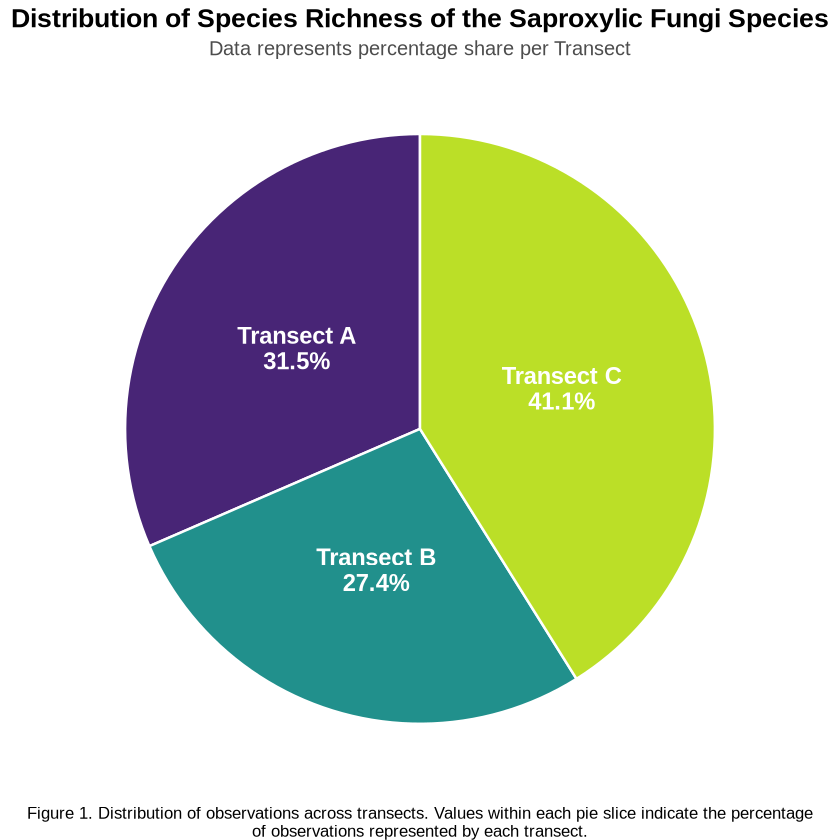

In [32]:
caption_text <- paste0(
    "Figure 1. Distribution of observations across transects. ",
    "Values within each pie slice indicate the percentage of ",
    "observations represented by each transect."
)

figure1 <- make_pie_chart(plot_data, plot_data$value, plot_data$group, plot_data$label) +
    labs(
        title = "Distribution of Species Richness of the Saproxylic Fungi Species",
        subtitle = "Data represents percentage share per Transect",
        caption = str_wrap(caption_text, width = 110)
    ) +
    theme(
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30"),
        plot.caption = element_text(hjust = 0.5, size = 10),
        legend.position = "none"
    )

figure1

#### 2.1.3. Species Frequency by Transect with Species List

In [33]:
# One transect
small_A <- (
    saproxylic_df %>%
        filter(A > 0 & A <= 100 & B == 0 & C == 0) %>%
        mutate(occurrence = paste("A:", A, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

small_B <- (
    saproxylic_df %>%
        filter(A == 0 & B > 0 & B <= 100 & C == 0) %>%
        mutate(occurrence = paste("B:", B, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

small_C <- (
    saproxylic_df %>%
        filter(A == 0 & B == 0 & C > 0 & C <= 100) %>%
        mutate(occurrence = paste("C:", C, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

large_A <- (
    saproxylic_df %>%
        filter(A > 100 & B == 0 & C == 0) %>%
        mutate(occurrence = paste("A:", A, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

large_B <- (
    saproxylic_df %>%
        filter(A == 0 & B > 100 & C == 0) %>%
        mutate(occurrence = paste("B:", B, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

large_C <- (
    saproxylic_df %>%
        filter(A == 0 & B == 0 & C > 100) %>%
        mutate(occurrence = paste("C:", C, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

In [34]:
# Two and three transects
AB <- (
    saproxylic_df %>%
        filter(A > 0 & B > 0 & C == 0) %>%
        mutate(occurrence = paste("A:", A, ", B:", B, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

AC <- (
    saproxylic_df %>%
        filter(A > 0 & B == 0 & C > 0) %>%
        mutate(occurrence = paste("A:", A, ", C:", C, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

BC <- (
    saproxylic_df %>%
        filter(A == 0 & B > 0 & C > 0) %>%
        mutate(occurrence = paste("B:", B, ", C:", C, sep=""))%>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

ABC <- (
    saproxylic_df %>%
        filter(A > 0 & B > 0 & C > 0) %>%
        mutate(occurrence = paste("A:", A, ", B:", B, ", C:", C, sep="")) %>%
        rownames_to_column(var = "species") %>%
        mutate(label=paste(species, " (", occurrence, ")", sep=""))
)$label

In [35]:
species_frequency_list <- list(
    "A" = c(small_A, large_A, AB, AC),
    "B" = c(small_B, large_B, AB, BC),
    "C" = c(small_C, large_C, AC, BC)
)
species_frequency_list

$A
 [1] "Exidia (A:3)"               "Lachnellula (A:10)"        
 [3] "Lenzites (A:3)"             "Stereum (A:3)"             
 [5] "Metulodontia (A:542)"       "Tympanis (A:23, B:3)"      
 [7] "Arachnopeziza (A:7, C:195)" "Cistella (A:14, C:40)"     
 [9] "Neoantrodia (A:6, C:50)"    "Pleurotus (A:7, C:5)"      
[11] "Scutellinia (A:87, C:1061)" "Trechispora (A:11, C:11)"  

$B
[1] "Atheliachaete (B:3)"      "Botryobasidium (B:6)"    
[3] "Pholiota (B:7)"           "Sistotremastrum (B:56)"  
[5] "Entoleuca (B:137)"        "Skvortzovia (B:442)"     
[7] "Tympanis (A:23, B:3)"     "Ascocoryne (B:70, C:37)" 
[9] "Coniophora (B:120, C:48)"

$C
 [1] "Claussenomyces (C:5)"       "Graphilbum (C:8)"          
 [3] "Hymenochaete (C:3)"         "Hyphodontia (C:7)"         
 [5] "Lentinula (C:3)"            "Oliveonia (C:22)"          
 [7] "Orbilia (C:9)"              "Patinella (C:5)"           
 [9] "Teichospora (C:3)"          "Xylaria (C:3)"             
[11] "Corticium (C:196)"          "Arachnopeziza (A:7, C:195)"
[13] "Cistella (A:14, C:40)"      "Neoantrodia (A:6, C:50)"   
[15] "Pleurotus (A:7, C:5)"       "Scutellinia (A:87, C:1061)"
[17] "Trechispora (A:11, C:11)"   "Ascocoryne (B:70, C:37)"   
[19] "Coniophora (B:120, C:48)"

In [36]:
# 1. Find the maximum length in your list (which is 18)
max_len <- max(sapply(species_frequency_list, length))

# 2. Pad shorter elements with empty string
padded_list <- lapply(species_frequency_list, function(x) {
  c(x, rep("", max_len - length(x)))
})

# 3. Convert safely to a data frame
species_frequency_df <- as.data.frame(padded_list)

In [37]:
# 4. Create the HTML table
table2 <- species_frequency_df %>%
    gt() %>% 
    cols_label(
        A = md("**Transect A**"),
        B = md("**Transect B**"),
        C = md('**Transect C**')
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md("**Table 2:** Distribution of saproxylic fungi species across transects. Numbers in parentheses indicate the frequency of occurrence for each species.")
    )

In [38]:
table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html() 

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 2: Distribution of saproxylic fungi species across transects. Numbers in parentheses indicate the frequency of occurrence for each species. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="A" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect A 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="B" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect B 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect C 
 
 
 
 Exidia (A:3) 
 Atheliachaete (B:3) 
 Claussenomyces (C:5) 
 Lachnellula (A:10) 
 Botryobasidium (B:6) 
 Graphilbum (C:8) 
 Lenzites (A:3) 
 Pholiota (B:7) 
 Hymenochaete (C:3) 
 Stereum (A:3) 
 Sistotremastrum (B:56) 
 Hyphodontia (C:7) 
 Metulodontia (A:542) 
 Entoleuca (B:137) 
 Lentinula (C:3) 
 Tympanis (A:23, B:3) 
 Skvortzovia (B:442) 
 Oliveonia (C:22) 
 Arachnopeziza (A:7, C:195) 
 Tympanis (A:23, B:3) 
 Orbilia (C:9) 
 Cistella (A:14, C:40) 
 Ascocoryne (B:70, C:37) 
 Patinella (C:5) 
 Neoantrodia (A:6, C:50) 
 Coniophora (B:120, C:48) 
 Teichospora (C:3) 
 Pleurotus (A:7, C:5) 
 
 Xylaria (C:3) 
 Scutellinia (A:87, C:1061) 
 
 Corticium (C:196) 
 Trechispora (A:11, C:11) 
 
 Arachnopeziza (A:7, C:195) 
 
 
 Cistella (A:14, C:40) 
 
 
 Neoantrodia (A:6, C:50) 
 
 
 Pleurotus (A:7, C:5) 
 
 
 Scutellinia (A:87, C:1061) 
 
 
 Trechispora (A:11, C:11) 
 
 
 Ascocoryne (B:70, C:37) 
 
 
 Coniophora (B:120, C:48)

#### 2.1.4. Species Frequency by Transect Occurrences

In [39]:
species_frequency_list <- list(
    "less_than_101" = c(small_A, small_B, small_C),
    "more_than_100" = c(large_A, large_B, large_C),
    "two_transects" = c(AB, AC, BC),
    "three_transects" = ABC
)
species_frequency_list

$less_than_101
 [1] "Exidia (A:3)"           "Lachnellula (A:10)"     "Lenzites (A:3)"        
 [4] "Stereum (A:3)"          "Atheliachaete (B:3)"    "Botryobasidium (B:6)"  
 [7] "Pholiota (B:7)"         "Sistotremastrum (B:56)" "Claussenomyces (C:5)"  
[10] "Graphilbum (C:8)"       "Hymenochaete (C:3)"     "Hyphodontia (C:7)"     
[13] "Lentinula (C:3)"        "Oliveonia (C:22)"       "Orbilia (C:9)"         
[16] "Patinella (C:5)"        "Teichospora (C:3)"      "Xylaria (C:3)"         

$more_than_100
[1] "Metulodontia (A:542)" "Entoleuca (B:137)"    "Skvortzovia (B:442)" 
[4] "Corticium (C:196)"   

$two_transects
[1] "Tympanis (A:23, B:3)"       "Arachnopeziza (A:7, C:195)"
[3] "Cistella (A:14, C:40)"      "Neoantrodia (A:6, C:50)"   
[5] "Pleurotus (A:7, C:5)"       "Scutellinia (A:87, C:1061)"
[7] "Trechispora (A:11, C:11)"   "Ascocoryne (B:70, C:37)"   
[9] "Coniophora (B:120, C:48)"  

$three_transects
 [1] "Ceraceomyces (A:81, B:4, C:948)"     "Collophora (A:33, B:10, C:93)"      
 [3] "Curvibasidium (A:4, B:5, C:60)"      "Hyaloscypha (A:600, B:253, C:933)"  
 [5] "Panellus (A:32, B:25, C:81)"         "Phanerochaete (A:29, B:33, C:45)"   
 [7] "Phellinus (A:186, B:24, C:21)"       "Pragmopora (A:81, B:157, C:153)"    
 [9] "Serpula (A:854, B:2251, C:5)"        "Trametes (A:8, B:3, C:13)"          
[11] "Xenasmatella (A:1944, B:3919, C:60)"

In [40]:
# 1. Find the maximum length in your list (which is 18)
max_len <- max(sapply(species_frequency_list, length))

# 2. Pad shorter elements with empty string
padded_list <- lapply(species_frequency_list, function(x) {
  c(x, rep("", max_len - length(x)))
})

# 3. Convert safely to a data frame
species_frequency_df <- as.data.frame(padded_list)

In [41]:
# 4. Create the HTML table
table3 <- species_frequency_df %>%
    gt() %>% 
    cols_label(
        less_than_101 = md("**<= 100 occurrences**"),
        more_than_100 = md("**> 100 occurrences**"),
        two_transects = md('**Two Transects**'),
        three_transects = md('**Three Transects**'),
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_spanner(
        label = md('**One Transect**'),
        columns = 1:2
    ) %>%
    tab_caption(
        caption = md("**Table 3:** Frequency of saproxylic fungi species across one, two, and three transects. Species occurring in only one transect are further categorized by an occurrence threshold of 100.")
    )

In [42]:
table3  %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html() 

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 3: Frequency of saproxylic fungi species across one, two, and three transects. Species occurring in only one transect are further categorized by an occurrence threshold of 100. <!--html_preserve-->
 
 
 
 One Transect 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="two_transects" align="center" bgcolor="#FFFFFF" valign="bottom"> Two Transects 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="three_transects" align="center" bgcolor="#FFFFFF" valign="bottom"> Three Transects 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="less_than_101" align="center" bgcolor="#FFFFFF" valign="bottom"> <= 100 occurrences 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="more_than_100" align="center" bgcolor="#FFFFFF" valign="bottom"> > 100 occurrences 
 
 
 
 Exidia (A:3) 
 Metulodontia (A:542) 
 Tympanis (A:23, B:3) 
 Ceraceomyces (A:81, B:4, C:948) 
 Lachnellula (A:10) 
 Entoleuca (B:137) 
 Arachnopeziza (A:7, C:195) 
 Collophora (A:33, B:10, C:93) 
 Lenzites (A:3) 
 Skvortzovia (B:442) 
 Cistella (A:14, C:40) 
 Curvibasidium (A:4, B:5, C:60) 
 Stereum (A:3) 
 Corticium (C:196) 
 Neoantrodia (A:6, C:50) 
 Hyaloscypha (A:600, B:253, C:933) 
 A

#### 2.1.5. Candidate Hypotheses **
1. The presence of reindeer in a forest reduces/eliminates
   * Ascocoryne (B:70, C:37)
   * Coniophora (B:120, C:48)
2. Unprotected forests introduces
   * Arachnopeziza (A:7, C:195)
   * Cistella (A:14, C:40) ***
   * Neoantrodia (A:6, C:50) ***
   * Pleurotus (A:7, C:5) ***
   * Scutellinia (A:87, C:1061)
   * Trechispora (A:11, C11) ***
3. The presence of reindeer in a conifer forest introduces
   * Metulodontia(A:543)
4. The absence of reindeer in a conifer forest introduces
   * Entoleuca(B:137)
   * Skvortzovia(B:442)
5. Do not exists in conifer forests or introduced by tourists
   * Corticium(C:196)

** Ignores single transect with less than 100 occurrences.

*** Might be too small of an observation

### 2.2. Transect + Wood.Texture

In [43]:
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Texture, saproxylic_community_df)
names(saproxylic_df)[1:2] = c("Transect", "Wood.Texture")

saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Texture) %>%
    summarise(
        across(3:last_col(), sum),                                 # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,".",Wood.Texture, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Texture)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names
saproxylic_df

,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,1,69,1,36
Atheliachaete,0,0,0,3,0,0
Botryobasidium,0,0,0,6,0,0
Ceraceomyces,42,39,1,3,928,20
Cistella,4,10,0,0,0,40
Claussenomyces,0,0,0,0,0,5
Collophora,13,20,5,5,91,2
Coniophora,0,0,71,49,2,46
Corticium,0,0,0,0,196,0


#### 2.2.1. Species Frequency by Transect and Wood Texture

In [44]:
species_presence <- as.data.frame( t(
    saproxylic_df %>%
        mutate(
            A_hardwood_presence = A.Hardwood > 0,
            A_softwood_presence = A.Softwood > 0,
            B_hardwood_presence = B.Hardwood > 0,
            B_softwood_presence = B.Softwood > 0,
            C_hardwood_presence = C.Hardwood > 0,
            C_softwood_presence = C.Softwood > 0,
        ) %>%
        select(
            A_hardwood_presence, A_softwood_presence, 
            B_hardwood_presence, B_softwood_presence, 
            C_hardwood_presence, C_softwood_presence, 
        )
))


counts <- as.list(rowSums(species_presence))

species_presence <- data.frame(
    Transect = c("A", "B", "C"),
    Description = c(
        "conifer forest with access of reindeer",
        "conifer forest without access of reindeer",
        "broadleaf forest and accessed to tourists"
    ),
    Hardwood = c(counts$A_hardwood_presence, counts$B_hardwood_presence, counts$C_hardwood_presence),
    Softwood = c(counts$A_softwood_presence, counts$B_softwood_presence, counts$C_softwood_presence)
)

rownames(species_presence) <- NULL
species_presence

Transect,Description,Hardwood,Softwood
<chr>,<chr>,<dbl>,<dbl>
A,conifer forest with access of reindeer,18,22
B,conifer forest without access of reindeer,14,20
C,broadleaf forest and accessed to tourists,22,26


In [45]:
table4 <- species_presence %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        Description = md("**Description**"),
        Hardwood = md('**Hardwood<br>(Birch)**'),
        Softwood = md('**Softwood<br>(Pine and Spruce)**')
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    tab_spanner(
      label = md('**Wood Texture**'),
      columns = c('Hardwood', 'Softwood')
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md("**Table 4:** Species richness of saproxylic fungi across transects, categorized by wood texture.")
    )

In [46]:
table4  %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html() 

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 4: Species richness of saproxylic fungi across transects, categorized by wood texture. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 
 Wood Texture 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Hardwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Hardwood (Birch) 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood (Pine and Spruce) 
 
 
 
 A 
 conifer forest with access of reindeer 
<td headers="Hardwood" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-c

In [47]:
plot_data <- species_presence %>%
    mutate(
        hardwood_percentage = Hardwood / sum(Hardwood) * 100,
        hardwood_label = paste0("Transect ", Transect, "\n", round(hardwood_percentage, 1), "%"),
        softwood_percentage = Softwood / sum(Softwood) * 100,
        softwood_label = paste0("Transect ", Transect, "\n", round(softwood_percentage, 1), "%")

    )

plot_data

Transect,Description,Hardwood,Softwood,hardwood_percentage,hardwood_label,softwood_percentage,softwood_label
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
A,conifer forest with access of reindeer,18,22,33.33333,Transect A 33.3%,32.35294,Transect A 32.4%
B,conifer forest without access of reindeer,14,20,25.92593,Transect B 25.9%,29.41176,Transect B 29.4%
C,broadleaf forest and accessed to tourists,22,26,40.74074,Transect C 40.7%,38.23529,Transect C 38.2%


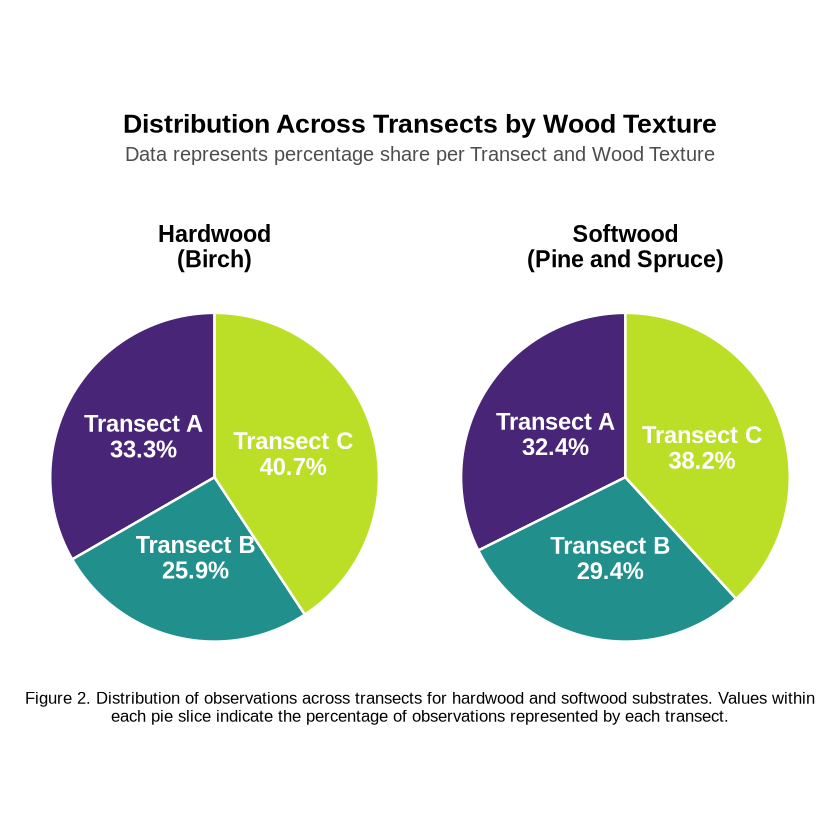

In [48]:
hardwood_pie_chart <- make_pie_chart(plot_data, plot_data$hardwood_percentage, plot_data$Transect, plot_data$hardwood_label) +
    labs(title = "Hardwood\n(Birch)") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

softwood_pie_chart <- make_pie_chart(plot_data, plot_data$softwood_percentage, plot_data$Transect, plot_data$softwood_label) +
    labs(title = "Softwood\n(Pine and Spruce)") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
        legend.position = "none"
    )

caption_text <- paste0(
    "Figure 2. Distribution of observations across transects for hardwood ",
    "and softwood substrates. Values within each pie slice indicate the ",
    "percentage of observations represented by each transect."
)

title_and_caption <- plot_annotation(
    title = "Distribution Across Transects by Wood Texture",,
    subtitle = "Data represents percentage share per Transect and Wood Texture",
    caption = str_wrap(caption_text, width = 110),
    theme = theme(
        plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, size = 12, color = "grey30", margin = margin(b=30)),
        plot.caption = element_text(hjust = 0.5, size = 10)
    )
)

combined_pie_chart <-
    hardwood_pie_chart + softwood_pie_chart + title_and_caption    

figure2 <- combined_pie_chart
figure2

#### 2.2.2. Unique Transect Species by Wood Texture

In [49]:
head(saproxylic_df)

,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,1,69,1,36
Atheliachaete,0,0,0,3,0,0
Botryobasidium,0,0,0,6,0,0
Ceraceomyces,42,39,1,3,928,20
Cistella,4,10,0,0,0,40
Claussenomyces,0,0,0,0,0,5


In [50]:
unique_A_hardwood <- saproxylic_df %>% 
    filter(
        A.Hardwood > 0 & 
        A.Softwood == 0 & 
        B.Hardwood == 0 &
        B.Softwood == 0 &
        C.Hardwood == 0 &
        C.Softwood == 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", A.Hardwood, ")", sep=""))

unique_A_hardwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


In [51]:
A_hardwood <- saproxylic_df %>% 
    filter(
        A.Hardwood > 0 
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", A.Hardwood, ")", sep=""))

A_hardwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Ceraceomyces,42,39,1,3,928,20,Ceraceomyces (42)
Cistella,4,10,0,0,0,40,Cistella (4)
Collophora,13,20,5,5,91,2,Collophora (13)
Curvibasidium,3,1,0,5,49,11,Curvibasidium (3)
Hyaloscypha,167,433,118,135,279,654,Hyaloscypha (167)
Lenzites,2,1,0,0,0,0,Lenzites (2)
Metulodontia,2,540,0,0,0,0,Metulodontia (2)
Neoantrodia,5,1,0,0,0,50,Neoantrodia (5)
Panellus,31,1,0,25,54,27,Panellus (31)


In [52]:
B_hardwood <- saproxylic_df %>% 
    filter(
        B.Hardwood > 0 
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", B.Hardwood, ")", sep=""))

B_hardwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Ascocoryne,0,0,1,69,1,36,Ascocoryne (1)
Ceraceomyces,42,39,1,3,928,20,Ceraceomyces (1)
Collophora,13,20,5,5,91,2,Collophora (5)
Coniophora,0,0,71,49,2,46,Coniophora (71)
Entoleuca,0,0,86,51,0,0,Entoleuca (86)
Hyaloscypha,167,433,118,135,279,654,Hyaloscypha (118)
Phanerochaete,24,5,1,32,28,17,Phanerochaete (1)
Phellinus,77,109,6,18,2,19,Phellinus (6)
Pragmopora,40,41,102,55,27,126,Pragmopora (102)


In [53]:
unique_A_softwood <- saproxylic_df %>% 
    filter(
        A.Hardwood == 0 & 
        A.Softwood > 0 & 
        B.Hardwood == 0 &
        B.Softwood == 0 &
        C.Hardwood == 0 &
        C.Softwood == 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", A.Softwood, ")", sep=""))
unique_A_softwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Exidia,0,3,0,0,0,0,Exidia (3)
Lachnellula,0,10,0,0,0,0,Lachnellula (10)
Stereum,0,3,0,0,0,0,Stereum (3)


In [54]:
unique_B_hardwood <- saproxylic_df %>% 
    filter(
        A.Hardwood == 0 & 
        A.Softwood == 0 & 
        B.Hardwood > 0 &
        B.Softwood == 0 &
        C.Hardwood == 0 &
        C.Softwood == 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", B.Hardwood, ")", sep=""))

unique_B_hardwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>


In [55]:
unique_B_softwood <- saproxylic_df %>% 
    filter(
        A.Hardwood == 0 & 
        A.Softwood == 0 & 
        B.Hardwood == 0 &
        B.Softwood > 0 &
        C.Hardwood == 0 &
        C.Softwood == 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", B.Softwood, ")", sep=""))

unique_B_softwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Atheliachaete,0,0,0,3,0,0,Atheliachaete (3)
Botryobasidium,0,0,0,6,0,0,Botryobasidium (6)
Pholiota,0,0,0,7,0,0,Pholiota (7)


In [56]:
unique_C_hardwood <- saproxylic_df %>% 
    filter(
        A.Hardwood == 0 & 
        A.Softwood == 0 & 
        B.Hardwood == 0 &
        B.Softwood == 0 &
        C.Hardwood > 0 &
        C.Softwood == 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", C.Hardwood, ")", sep=""))

unique_C_hardwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Corticium,0,0,0,0,196,0,Corticium (196)
Lentinula,0,0,0,0,3,0,Lentinula (3)
Teichospora,0,0,0,0,3,0,Teichospora (3)


In [57]:
unique_C_softwood <- saproxylic_df %>% 
    filter(
        A.Hardwood == 0 & 
        A.Softwood == 0 & 
        B.Hardwood == 0 &
        B.Softwood == 0 &
        C.Hardwood == 0 &
        C.Softwood > 0
    ) %>%
    rownames_to_column(var = "species") %>%
    mutate(label=paste(species, " (", C.Softwood, ")", sep=""))

unique_C_softwood

species,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood,label
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Claussenomyces,0,0,0,0,0,5,Claussenomyces (5)
Graphilbum,0,0,0,0,0,8,Graphilbum (8)
Orbilia,0,0,0,0,0,9,Orbilia (9)
Patinella,0,0,0,0,0,5,Patinella (5)
Xylaria,0,0,0,0,0,3,Xylaria (3)


In [58]:
species_frequency_list <- list(
    #"A.Hardwood" = unique_A_hardwood$label, # no species
    "A.Softwood" = unique_A_softwood$label,
    #"B.Hardwood" = unique_B_hardwood$label, # no species
    "B.Softwood" = unique_B_softwood$label,
    "C.Hardwood" = unique_C_hardwood$label,
    "C.Softwood" = unique_C_softwood$label
)
species_frequency_list

$A.Softwood
[1] "Exidia (3)"       "Lachnellula (10)" "Stereum (3)"     

$B.Softwood
[1] "Atheliachaete (3)"  "Botryobasidium (6)" "Pholiota (7)"      

$C.Hardwood
[1] "Corticium (196)" "Lentinula (3)"   "Teichospora (3)"

$C.Softwood
[1] "Claussenomyces (5)" "Graphilbum (8)"     "Orbilia (9)"       
[4] "Patinella (5)"      "Xylaria (3)"

In [59]:
# 1. Find the maximum length in your list (which is 18)
max_len <- max(sapply(species_frequency_list, length))

# 2. Pad shorter elements with empty string
padded_list <- lapply(species_frequency_list, function(x) {
  c(x, rep("", max_len - length(x)))
})

# 3. Convert safely to a data frame
species_frequency_df <- as.data.frame(padded_list)

species_frequency_df

A.Softwood,B.Softwood,C.Hardwood,C.Softwood
<chr>,<chr>,<chr>,<chr>
Exidia (3),Atheliachaete (3),Corticium (196),Claussenomyces (5)
Lachnellula (10),Botryobasidium (6),Lentinula (3),Graphilbum (8)
Stereum (3),Pholiota (7),Teichospora (3),Orbilia (9)
,,,Patinella (5)
,,,Xylaria (3)


In [60]:
# 4. Create the HTML table
table5 <- species_frequency_df %>%
    gt() %>% 
    cols_label(
        #A.Hardwood = md("**Hardwood**"),  # no species
        A.Softwood = md("**Softwood**"),
        # B.Hardwood = md("**Hardwood**"), # no species
        B.Softwood = md("**Softwood**"),
        C.Hardwood = md("**Hardwood**"),
        C.Softwood = md("**Softwood**")
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_spanner(
        label = md('**Transect A**'),
        columns = 1
    ) %>%
    tab_spanner(
        label = md('**Transect B**'),
        columns = 2
    ) %>%
    tab_spanner(
        label = md('**Transect C**'),
        columns = 3:4
    ) %>%
    tab_caption(
        caption = md("**Table 5:** Saproxylic fungi species unique across transects by wood texture")
    )

In [61]:
table5  %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html() 

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 5: Saproxylic fungi species unique across transects by wood texture <!--html_preserve-->
 
 
 
 Transect A 
 
 
 Transect B 
 
 
 Transect C 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="A.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="B.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C.Hardwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Hardwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 
 
 
 Exidia (3) 
 Atheliachaete (3) 
 Corticium (196) 
 Claussenomyces (5) 
 Lachnellula (10) 
 Botryobasidium (6) 
 Lentinula (3) 
 Graphilbum (8) 
 Stereum (3) 
 Pholiota (7) 
 Teichospora (3) 
 Orbilia (9) 
 
 
 
 Patinella (5) 
 
 
 
 Xylaria (3)

## 3. Results

This study focused on saproxylic fungi communities across three distinct environmental transects. The first transect (Transect A) consists of a conifer forest with reindeer access; the second (Transect B) is a conifer forest without reindeer access; and the third (Transect C) is a broadleaf forest with tourist access. The study identified 43 saproxylic fungi species, which were evenly distributed across the three transects. Table 1 displays the number of species found in each transect, while Figure 1 illustrates this distribution.

In [62]:
display_gt_html(table1)

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1: Species richness of saproxylic fungi across transects <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Richness" align="center" bgcolor="#FFFFFF" valign="bottom"> Richness 
 
 
 
 A 
 conifer forest with access of reindeer 
<td headers="Richness" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" valign="middle" align="right">23 
 B 
 conifer forest without access of reindeer 
<td headers="Richness" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" valign="middle" align="ri

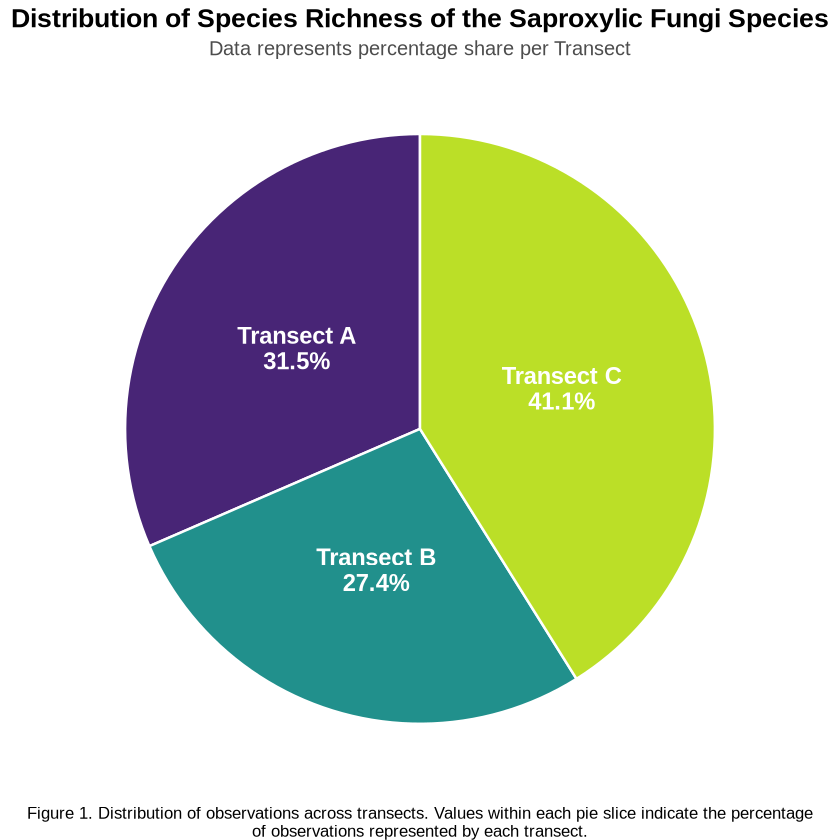

In [63]:
figure1

Table 2 lists the saproxylic fungi species identified in each transect. As species may occur in multiple locations, the numbers following each species name indicate its frequency of occurrence across the transects.

In [64]:
display_gt_html(table2)

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 2: Distribution of saproxylic fungi species across transects. Numbers in parentheses indicate the frequency of occurrence for each species. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="A" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect A 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="B" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect B 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect C 
 
 
 
 Exidia (A:3) 
 Atheliachaete (B:3) 
 Claussenomyces (C:5) 
 Lachnellula (A:10) 
 Botryobasidium (B:6) 
 Graphilbum (C:8) 
 Lenzites (A:3) 
 Pholiota (B:7) 
 Hymenochaete (C:3) 
 Stereum (A:3) 
 Sistotremastrum (B:56) 
 Hyphodontia (C:7) 
 Metulodontia (A:542) 
 Entoleuca (B:137) 
 Lentinula (C:3) 
 Tympanis (A:23, B:3) 
 Skvortzovia (B:442) 
 Oliveonia (C:22) 
 Arachnopeziza (A:7, C:195) 
 Tympanis (A:23, B:3) 
 Orbilia (C:9) 
 Cistella (A:14, C:40) 
 Ascocoryne (B:70, C:37) 
 Patinella (C:5) 
 Neoantrodia (A:6, C:50) 
 Coniophora (B:120, C:48) 
 Teichospora (C:3) 
 Pleurotus (A:7, C:5) 
 
 Xylaria (C:3) 
 Scutellinia (A:87, C:1061) 
 
 Corticium (C:196) 
 Trechispora (A:11, C:11) 
 
 Arachnopeziza (A:7, C:195) 
 
 
 Cistella (A:14, C:40) 
 
 
 Neoantrodia (A:6, C:50) 
 
 
 Pleurotus (A:7, C:5) 
 
 
 Scutellinia (A:87, C:1061) 
 
 
 Trechispora (A:11, C:11) 
 
 
 Ascocoryne (B:70, C:37) 
 
 
 Coniophora (B:120, C:48)

Table 3 summarizes saproxylic fungal species according to the number of transects in which they occurred. Species recorded in only one transect were further categorized using an occurrence threshold of 100.

In [65]:
display_gt_html(table3)

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 3: Frequency of saproxylic fungi species across one, two, and three transects. Species occurring in only one transect are further categorized by an occurrence threshold of 100. <!--html_preserve-->
 
 
 
 One Transect 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="two_transects" align="center" bgcolor="#FFFFFF" valign="bottom"> Two Transects 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="three_transects" align="center" bgcolor="#FFFFFF" valign="bottom"> Three Transects 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="less_than_101" align="center" bgcolor="#FFFFFF" valign="bottom"> <= 100 occurrences 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="more_than_100" align="center" bgcolor="#FFFFFF" valign="bottom"> > 100 occurrences 
 
 
 
 Exidia (A:3) 
 Metulodontia (A:542) 
 Tympanis (A:23, B:3) 
 Ceraceomyces (A:81, B:4, C:948) 
 Lachnellula (A:10) 
 Entoleuca (B:137) 
 Arachnopeziza (A:7, C:195) 
 Collophora (A:33, B:10, C:93) 
 Lenzites (A:3) 
 Skvortzovia (B:442) 
 Cistella (A:14, C:40) 
 Curvibasidium (A:4, B:5, C:60) 
 Stereum (A:3) 
 Corticium (C:196) 
 Neoantrodia (A:6, C:50) 
 Hyaloscypha (A:600, B:253, C:933) 
 A

Saproxylic fungi diversity was evaluated using pine, spruce, and birch mycopins. Across all three transects, softwood dowels supported higher species richness than hardwood. Specifically, species counts (hardwood vs. softwood) were 18:22 in Transect A, 14:20 in Transect B, and 22:26 in Transect C. Table 4 displays the number of species found in each transect for each wood texture, while Figure 2 illustrates this distribution.

In [66]:
display_gt_html(table4)

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 4: Species richness of saproxylic fungi across transects, categorized by wood texture. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Description" align="center" bgcolor="#FFFFFF" valign="bottom"> Description 
 
 Wood Texture 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Hardwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Hardwood (Birch) 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood (Pine and Spruce) 
 
 
 
 A 
 conifer forest with access of reindeer 
<td headers="Hardwood" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-c

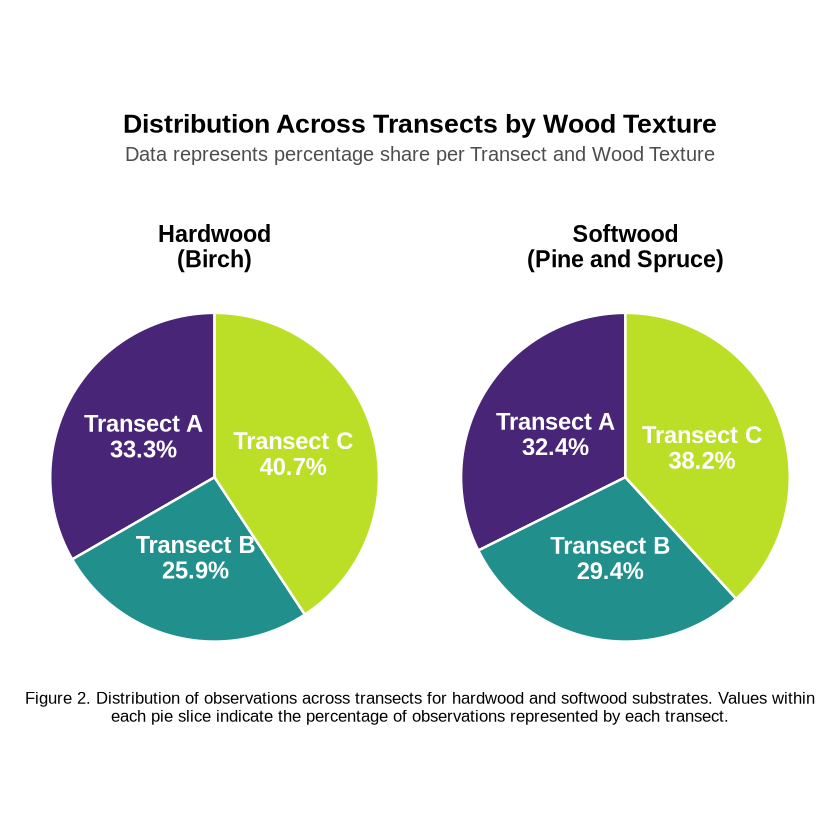

In [67]:
figure2

Table 5 summarizes the saproxylic fungi species unique to each wood type across the studied transects. Specifically, three unique species were identified on softwood substrates in both Transect A and Transect B, as well as on hardwood in Transect C. In Transect C, an additional five unique species were found on softwood. Notably, no species were unique to hardwood substrates within Transects A or B.

In [68]:
display_gt_html(table5)

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 5: Saproxylic fungi species unique across transects by wood texture <!--html_preserve-->
 
 
 
 Transect A 
 
 
 Transect B 
 
 
 Transect C 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="A.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="B.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C.Hardwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Hardwood 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="C.Softwood" align="center" bgcolor="#FFFFFF" valign="bottom"> Softwood 
 
 
 
 Exidia (3) 
 Atheliachaete (3) 
 Corticium (196) 
 Claussenomyces (5) 
 Lachnellula (10) 
 Botryobasidium (6) 
 Lentinula (3) 
 Graphilbum (8) 
 Stereum (3) 
 Pholiota (7) 
 Teichospora (3) 
 Orbilia (9) 
 
 
 
 Patinella (5) 
 
 
 
 Xylaria (3)

## A. Session Info

In [69]:
sessionInfo()

R version 4.5.3 (2026-03-11)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 24.04.3 LTS

Matrix products: default
BLAS/LAPACK: /opt/conda/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] viridis_0.6.5     viridisLite_0.4.3 vegan_2.7-5       permute_0.9-10   
 [5] tidyr_1.3.2       tibble_3.3.1      stringr_1.6.0     scales_1.4.0     
 [9] readr_2.2.0       patchwork_1.3.2   labdsv_2.3-1      mgcv_1.9-4       
[13] nlme_3.1-170      IRdisplay_1.1     iNEXT_3.0.2       gt_1.3.0         
[17] ggplot2_4

## B. Citations

In [70]:
citation("gt")

To cite package ‘gt’ in publications use:

  Iannone R, Cheng J, Schloerke B, Haughton S, Hughes E, Lauer A,
  François R, Seo J, Brevoort K, Roy O (2026). _gt: Easily Create
  Presentation-Ready Display Tables_. doi:10.32614/CRAN.package.gt
  <https://doi.org/10.32614/CRAN.package.gt>, R package version 1.3.0,
  <https://CRAN.R-project.org/package=gt>.

A BibTeX entry for LaTeX users is

  @Manual{,
    title = {gt: Easily Create Presentation-Ready Display Tables},
    author = {Richard Iannone and Joe Cheng and Barret Schloerke and Shannon Haughton and Ellis Hughes and Alexandra Lauer and Romain François and JooYoung Seo and Ken Brevoort and Olivier Roy},
    year = {2026},
    note = {R package version 1.3.0},
    url = {https://CRAN.R-project.org/package=gt},
    doi = {10.32614/CRAN.package.gt},
  }

In [71]:
citation("patchwork")

To cite package ‘patchwork’ in publications use:

  Pedersen T (2025). _patchwork: The Composer of Plots_.
  doi:10.32614/CRAN.package.patchwork
  <https://doi.org/10.32614/CRAN.package.patchwork>, R package version
  1.3.2, <https://CRAN.R-project.org/package=patchwork>.

A BibTeX entry for LaTeX users is

  @Manual{,
    title = {patchwork: The Composer of Plots},
    author = {Thomas Lin Pedersen},
    year = {2025},
    note = {R package version 1.3.2},
    url = {https://CRAN.R-project.org/package=patchwork},
    doi = {10.32614/CRAN.package.patchwork},
  }

In [72]:
citation("tidyverse")

To cite package ‘tidyverse’ in publications use:

  Wickham H, Averick M, Bryan J, Chang W, McGowan LD, François R,
  Grolemund G, Hayes A, Henry L, Hester J, Kuhn M, Pedersen TL, Miller
  E, Bache SM, Müller K, Ooms J, Robinson D, Seidel DP, Spinu V,
  Takahashi K, Vaughan D, Wilke C, Woo K, Yutani H (2019). “Welcome to
  the tidyverse.” _Journal of Open Source Software_, *4*(43), 1686.
  doi:10.21105/joss.01686 <https://doi.org/10.21105/joss.01686>.

A BibTeX entry for LaTeX users is

  @Article{,
    title = {Welcome to the {tidyverse}},
    author = {Hadley Wickham and Mara Averick and Jennifer Bryan and Winston Chang and Lucy D'Agostino McGowan and Romain François and Garrett Grolemund and Alex Hayes and Lionel Henry and Jim Hester and Max Kuhn and Thomas Lin Pedersen and Evan Miller and Stephan Milton Bache and Kirill Müller and Jeroen Ooms and David Robinson and Dana Paige Seidel and Vitalie Spinu and Kohske Takahashi and Davis Vaughan and Claus Wilke and Kara Woo and Hiroaki Yu